In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch

In [2]:
df = pd.read_csv("fetal_health.csv")

In [3]:
df.head()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
0,120.0,0.000,0.0,0.000,0.000,0.0,0.0,73.0,0.5,43.0,...,62.0,126.0,2.0,0.0,120.0,137.0,121.0,73.0,1.0,2.0
1,132.0,0.006,0.0,0.006,0.003,0.0,0.0,17.0,2.1,0.0,...,68.0,198.0,6.0,1.0,141.0,136.0,140.0,12.0,0.0,1.0
2,133.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.1,0.0,...,68.0,198.0,5.0,1.0,141.0,135.0,138.0,13.0,0.0,1.0
3,134.0,0.003,0.0,0.008,0.003,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,11.0,0.0,137.0,134.0,137.0,13.0,1.0,1.0
4,132.0,0.007,0.0,0.008,0.000,0.0,0.0,16.0,2.4,0.0,...,53.0,170.0,9.0,0.0,137.0,136.0,138.0,11.0,1.0,1.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2126 entries, 0 to 2125
Data columns (total 22 columns):
 #   Column                                                  Non-Null Count  Dtype  
---  ------                                                  --------------  -----  
 0   baseline value                                          2126 non-null   float64
 1   accelerations                                           2126 non-null   float64
 2   fetal_movement                                          2126 non-null   float64
 3   uterine_contractions                                    2126 non-null   float64
 4   light_decelerations                                     2126 non-null   float64
 5   severe_decelerations                                    2126 non-null   float64
 6   prolongued_decelerations                                2126 non-null   float64
 7   abnormal_short_term_variability                         2126 non-null   float64
 8   mean_value_of_short_term_variability             

In [5]:
df.describe()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
count,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.00000,...,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000,2126.000000
mean,133.303857,0.003178,0.009481,0.004366,0.001889,0.000003,0.000159,46.990122,1.332785,9.84666,...,93.579492,164.025400,4.068203,0.323612,137.452023,134.610536,138.090310,18.808090,0.320320,1.304327
std,9.840844,0.003866,0.046666,0.002946,0.002960,0.000057,0.000590,17.192814,0.883241,18.39688,...,29.560212,17.944183,2.949386,0.706059,16.381289,15.593596,14.466589,28.977636,0.610829,0.614377
min,106.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,12.000000,0.200000,0.00000,...,50.000000,122.000000,0.000000,0.000000,60.000000,73.000000,77.000000,0.000000,-1.000000,1.000000
25%,126.000000,0.000000,0.000000,0.002000,0.000000,0.000000,0.000000,32.000000,0.700000,0.00000,...,67.000000,152.000000,2.000000,0.000000,129.000000,125.000000,129.000000,2.000000,0.000000,1.000000
50%,133.000000,0.002000,0.000000,0.004000,0.000000,0.000000,0.000000,49.000000,1.200000,0.00000,...,93.000000,162.000000,3.000000,0.000000,139.000000,136.000000,139.000000,7.000000,0.000000,1.000000
75%,140.000000,0.006000,0.003000,0.007000,0.003000,0.000000,0.000000,61.000000,1.700000,11.00000,...,120.000000,174.000000,6.000000,0.000000,148.000000,145.000000,148.000000,24.000000,1.000000,1.000000
max,160.000000,0.019000,0.481000,0.015000,0.015000,0.001000,0.005000,87.000000,7.000000,91.00000,...,159.000000,238.000000,18.000000,10.000000,187.000000,182.000000,186.000000,269.000000,1.000000,3.000000


In [6]:
df.duplicated().sum()

np.int64(13)

In [7]:
df.corr()

,baseline value,accelerations,fetal_movement,uterine_contractions,light_decelerations,severe_decelerations,prolongued_decelerations,abnormal_short_term_variability,mean_value_of_short_term_variability,percentage_of_time_with_abnormal_long_term_variability,...,histogram_min,histogram_max,histogram_number_of_peaks,histogram_number_of_zeroes,histogram_mode,histogram_mean,histogram_median,histogram_variance,histogram_tendency,fetal_health
baseline value,1.000000,-0.080560,-0.033436,-0.146373,-0.159032,-0.053518,-0.104597,0.305570,-0.279607,0.285630,...,0.361619,0.275110,-0.113933,-0.004745,0.708993,0.723121,0.789246,-0.133938,0.293503,0.148151
accelerations,-0.080560,1.000000,0.048235,0.089674,-0.108615,-0.043018,-0.127749,-0.279577,0.207170,-0.373943,...,-0.154286,0.394147,0.190452,-0.006147,0.243610,0.270334,0.272849,0.125704,0.028420,-0.364066
fetal_movement,-0.033436,0.048235,1.000000,-0.068779,0.049228,-0.010976,0.265922,-0.103715,0.121314,-0.074096,...,-0.153917,0.099853,0.164654,-0.017749,-0.061192,-0.089671,-0.072329,0.179340,-0.001541,0.088010
uterine_contractions,-0.146373,0.089674,-0.068779,1.000000,0.285079,0.006788,0.077036,-0.232811,0.289679,-0.306608,...,-0.113323,0.122766,0.082693,0.057894,-0.104854,-0.187505,-0.140287,0.238582,-0.072314,-0.204894
light_decelerations,-0.159032,-0.108615,0.049228,0.285079,1.000000,0.107573,0.225611,-0.119152,0.562170,-0.271282,...,-0.553534,0.218043,0.397620,0.235296,-0.347233,-0.527354,-0.388586,0.564289,0.000072,0.058870
severe_decelerations,-0.053518,-0.043018,-0.010976,0.006788,0.107573,1.000000,0.012395,0.033949,0.034130,-0.030770,...,-0.071974,-0.021135,0.007024,0.043441,-0.215161,-0.158673,-0.160451,0.136421,-0.070483,0.131934
prolongued_decelerations,-0.104597,-0.127749,0.265922,0.077036,0.225611,0.012395,1.000000,0.046226,0.267011,-0.137333,...,-0.276764,0.120221,0.222860,0.056423,-0.436416,-0.488663,-0.444778,0.503301,-0.215405,0.484859
abnormal_short_term_variability,0.305570,-0.279577,-0.103715,-0.232811,-0.119152,0.033949,0.046226,1.000000,-0.430705,0.459413,...,0.275378,-0.111806,-0.167561,-0.149296,0.058363,0.074554,0.119960,-0.146434,-0.005748,0.471191
mean_value_of_short_term_variability,-0.279607,0.207170,0.121314,0.289679,0.562170,0.034130,0.267011,-0.430705,1.000000,-0.470259,...,-0.622569,0.409072,0.501430,0.266183,-0.307586,-0.445401,-0.336109,0.555852,-0.066140,-0.103382
percentage_of_time_with_abnormal_long_term_variability,0.285630,-0.373943,-0.074096,-0.306608,-0.271282,-0.030770,-0.137333,0.459413,-0.470259,1.000000,...,0.422834,-0.283183,-0.279301,-0.121784,0.165211,0.222321,0.186480,-0.281536,0.042481,0.426146


C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\1288423371.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='fetal_health', palette='viridis')


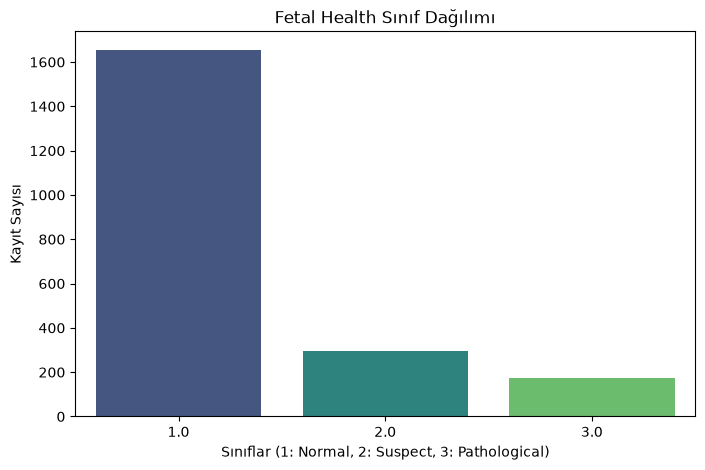

In [8]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='fetal_health', palette='viridis')
plt.title("Fetal Health Sınıf Dağılımı")
plt.xlabel("Sınıflar (1: Normal, 2: Suspect, 3: Pathological)")
plt.ylabel("Kayıt Sayısı")
plt.show()

C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\968583760.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='fetal_health', y=col, data=df, ax=axes[i], palette='viridis')
C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\968583760.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='fetal_health', y=col, data=df, ax=axes[i], palette='viridis')
C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\968583760.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='fetal_health', y=col, data=df, ax=axes[i], palette='viridis')
C:\Users\bjkef\A

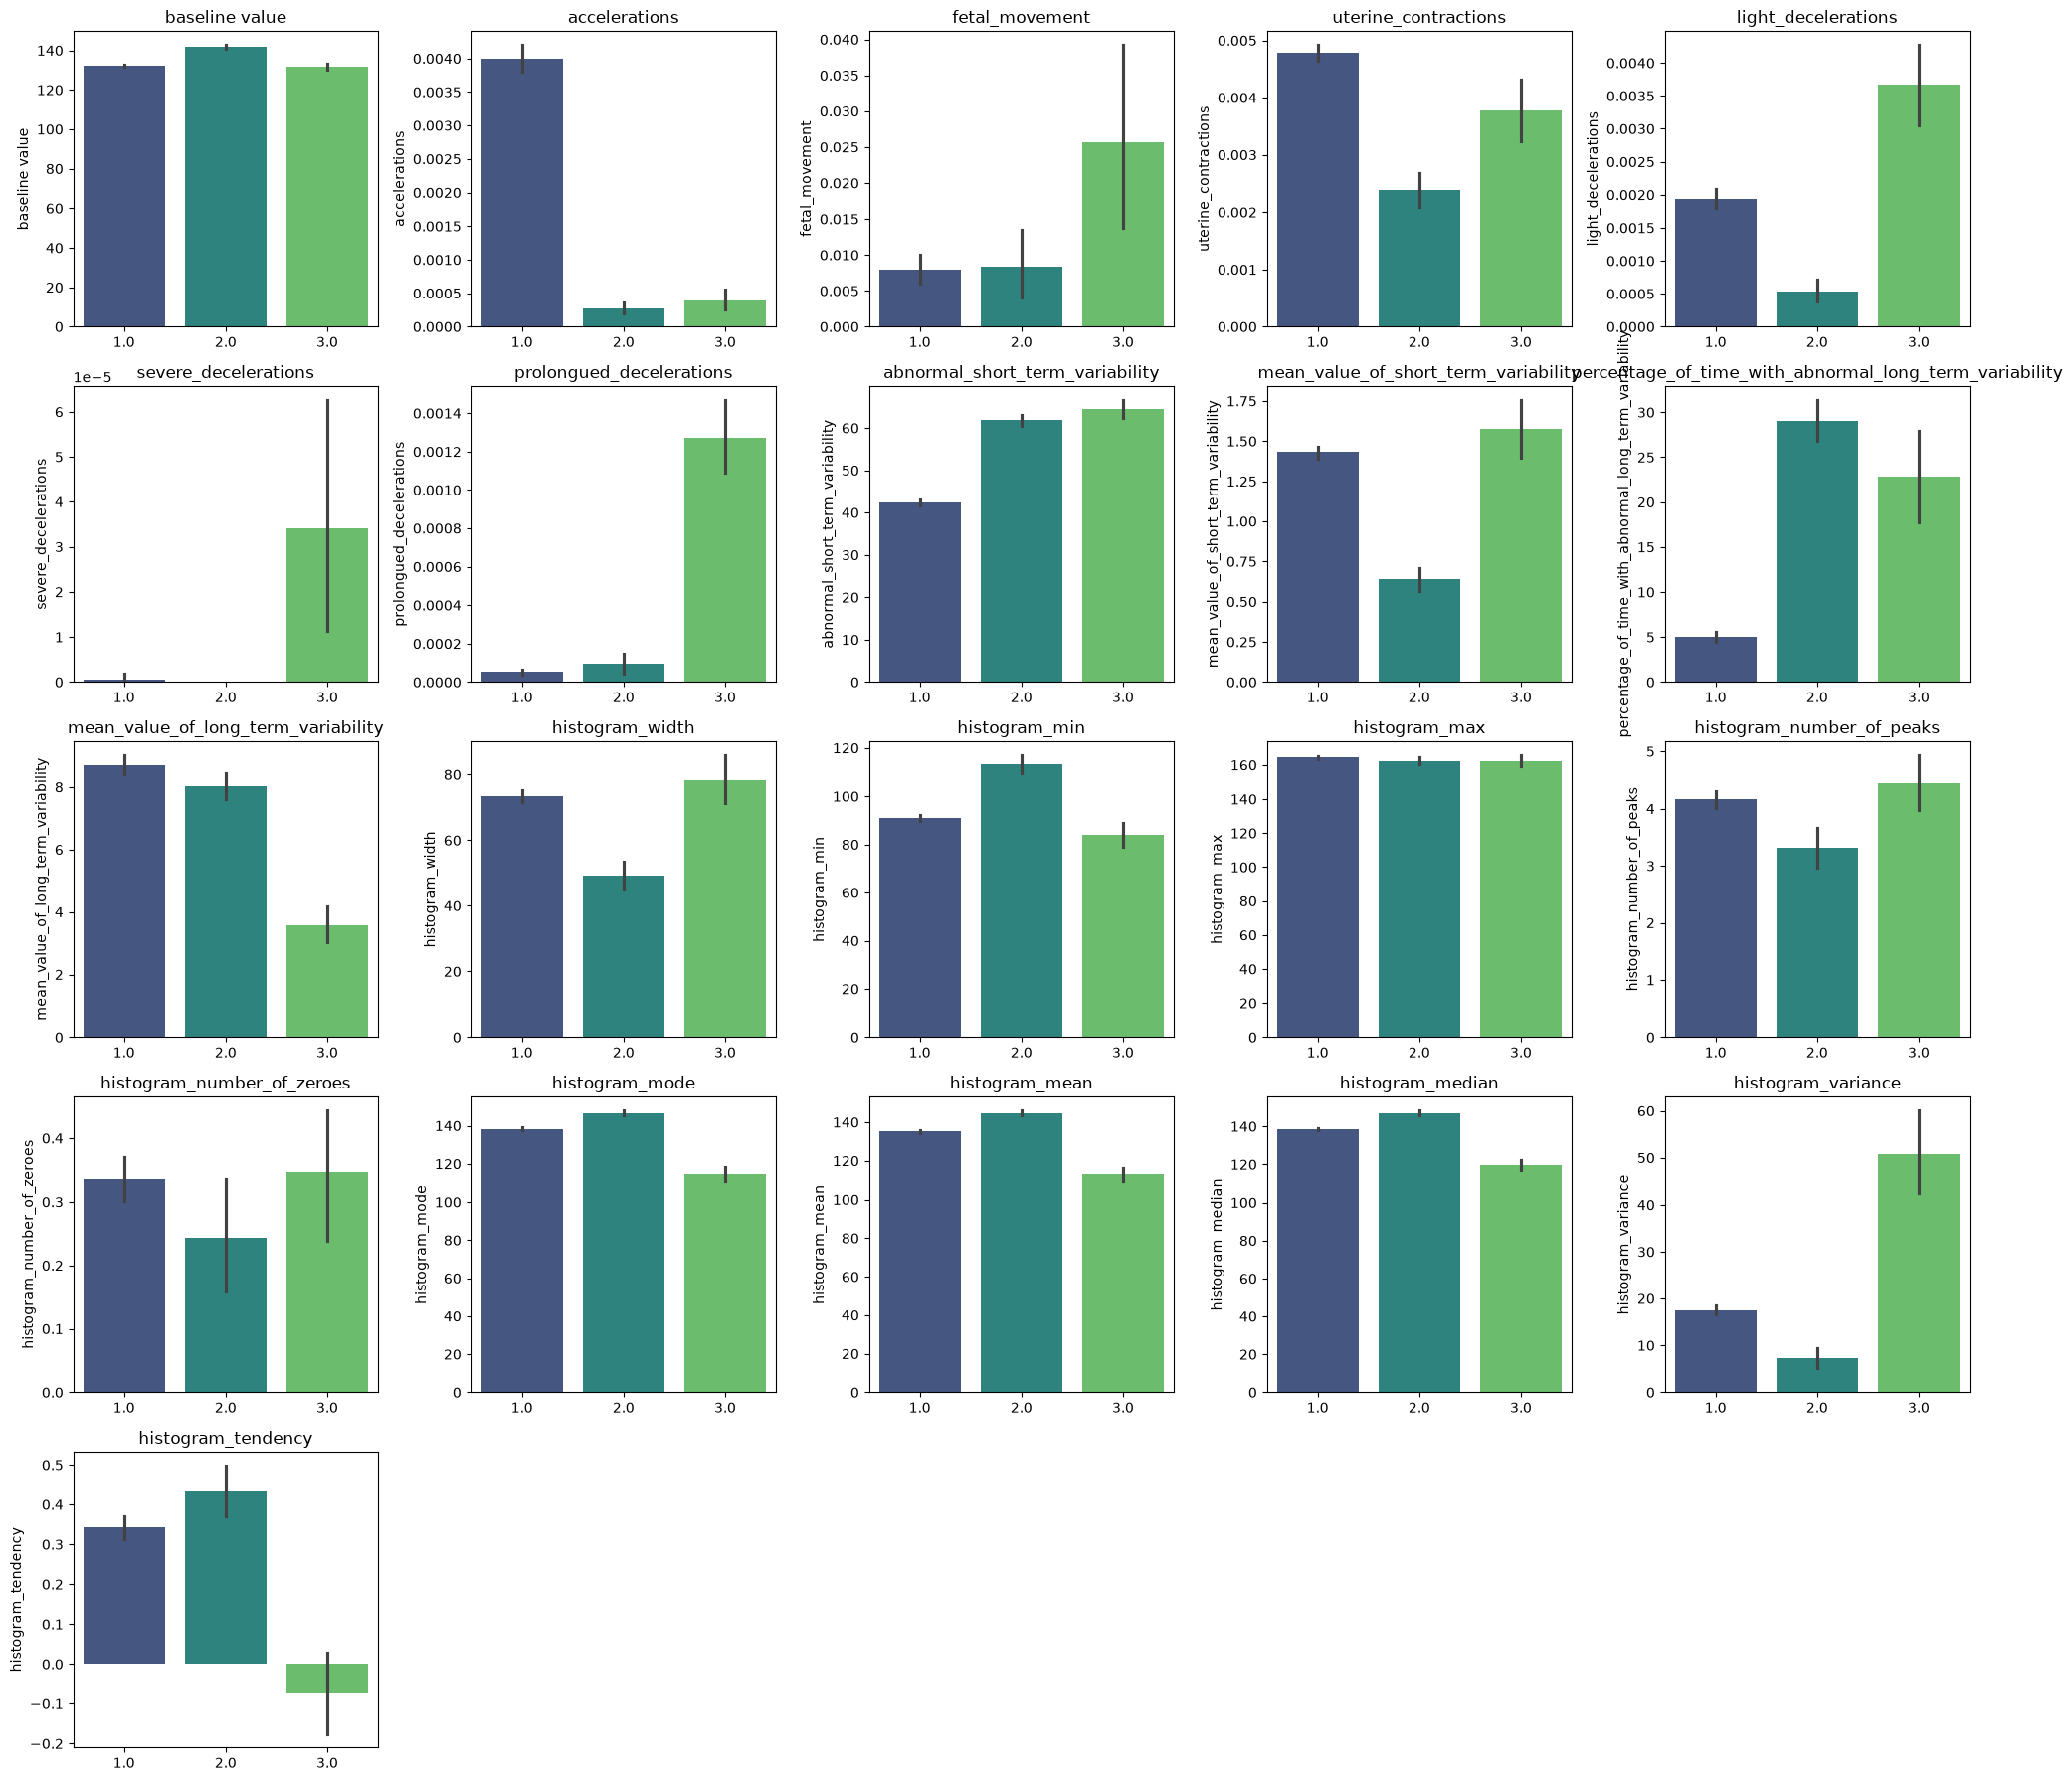

In [9]:
# Hedef değişkeni dışarıda bırakıp sadece özellikleri alıyoruz
features = df.columns[:-1]

# 5x5'lik bir grid oluştur (21 özellik için 25 alan açar)
fig, axes = plt.subplots(nrows=5, ncols=5, figsize=(20, 18))
axes = axes.flatten() # 2 boyutlu axes dizisini tek boyuta indirger

for i, col in enumerate(features):
    sns.barplot(x='fetal_health', y=col, data=df, ax=axes[i], palette='viridis')
    axes[i].set_title(col)
    axes[i].set_xlabel('') # Eksen yazısı kalabalık yapmasın diye siliyoruz

# 21 özellik çizildikten sonra geriye kalan 4 boş grafiği temizle
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

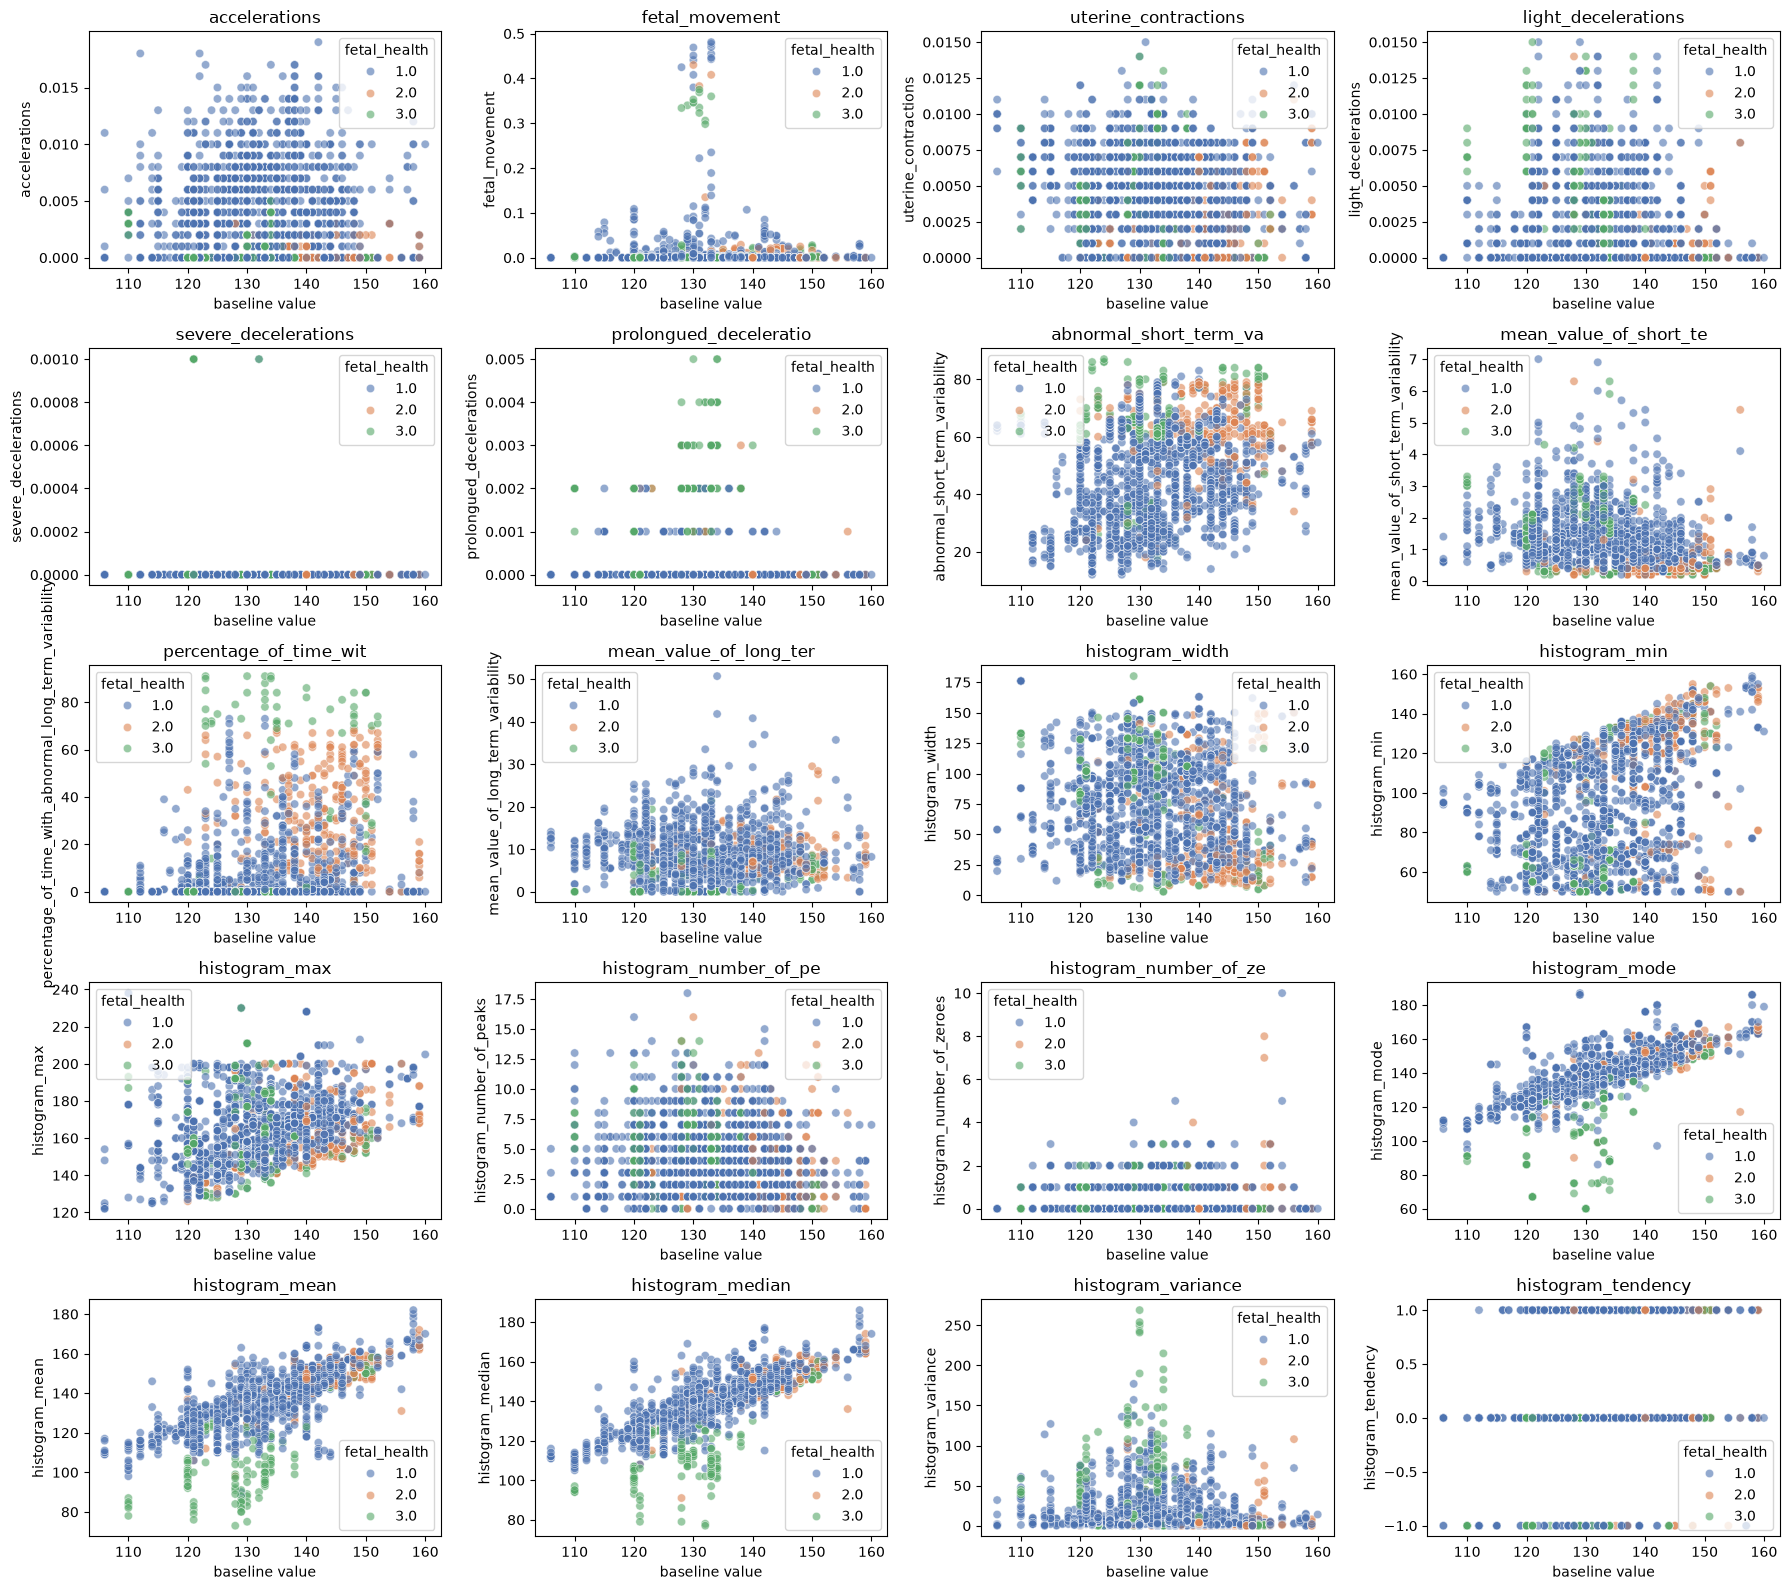

In [10]:
# Sadece çizdireceğimiz özellikleri ayırıyoruz (baseline value hariç 20 özellik)
plot_features = [col for col in features if col != 'baseline value']

# 20 özellik için tam uyan 5 satır, 4 sütunluk grid açıyoruz
fig1, axes1 = plt.subplots(nrows=5, ncols=4, figsize=(18, 16)) 
axes1 = axes1.flatten()

for i, col in enumerate(plot_features):
    sns.scatterplot(x='baseline value', y=col, hue='fetal_health', data=df, ax=axes1[i], palette='deep', alpha=0.6)
    axes1[i].set_title(col[:22]) # Başlıklar taşmasın diye kısaltıyoruz
    axes1[i].set_xlabel('baseline value')

plt.tight_layout()
plt.show()

C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\4250615568.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fetal_health', y=col, data=df, ax=axes2[i], palette='Set2')
C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\4250615568.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fetal_health', y=col, data=df, ax=axes2[i], palette='Set2')
C:\Users\bjkef\AppData\Local\Temp\ipykernel_20968\4250615568.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='fetal_health', y=col, data=df, ax=axes2[i], palette='Set2')
C:\Users\bjkef\AppD

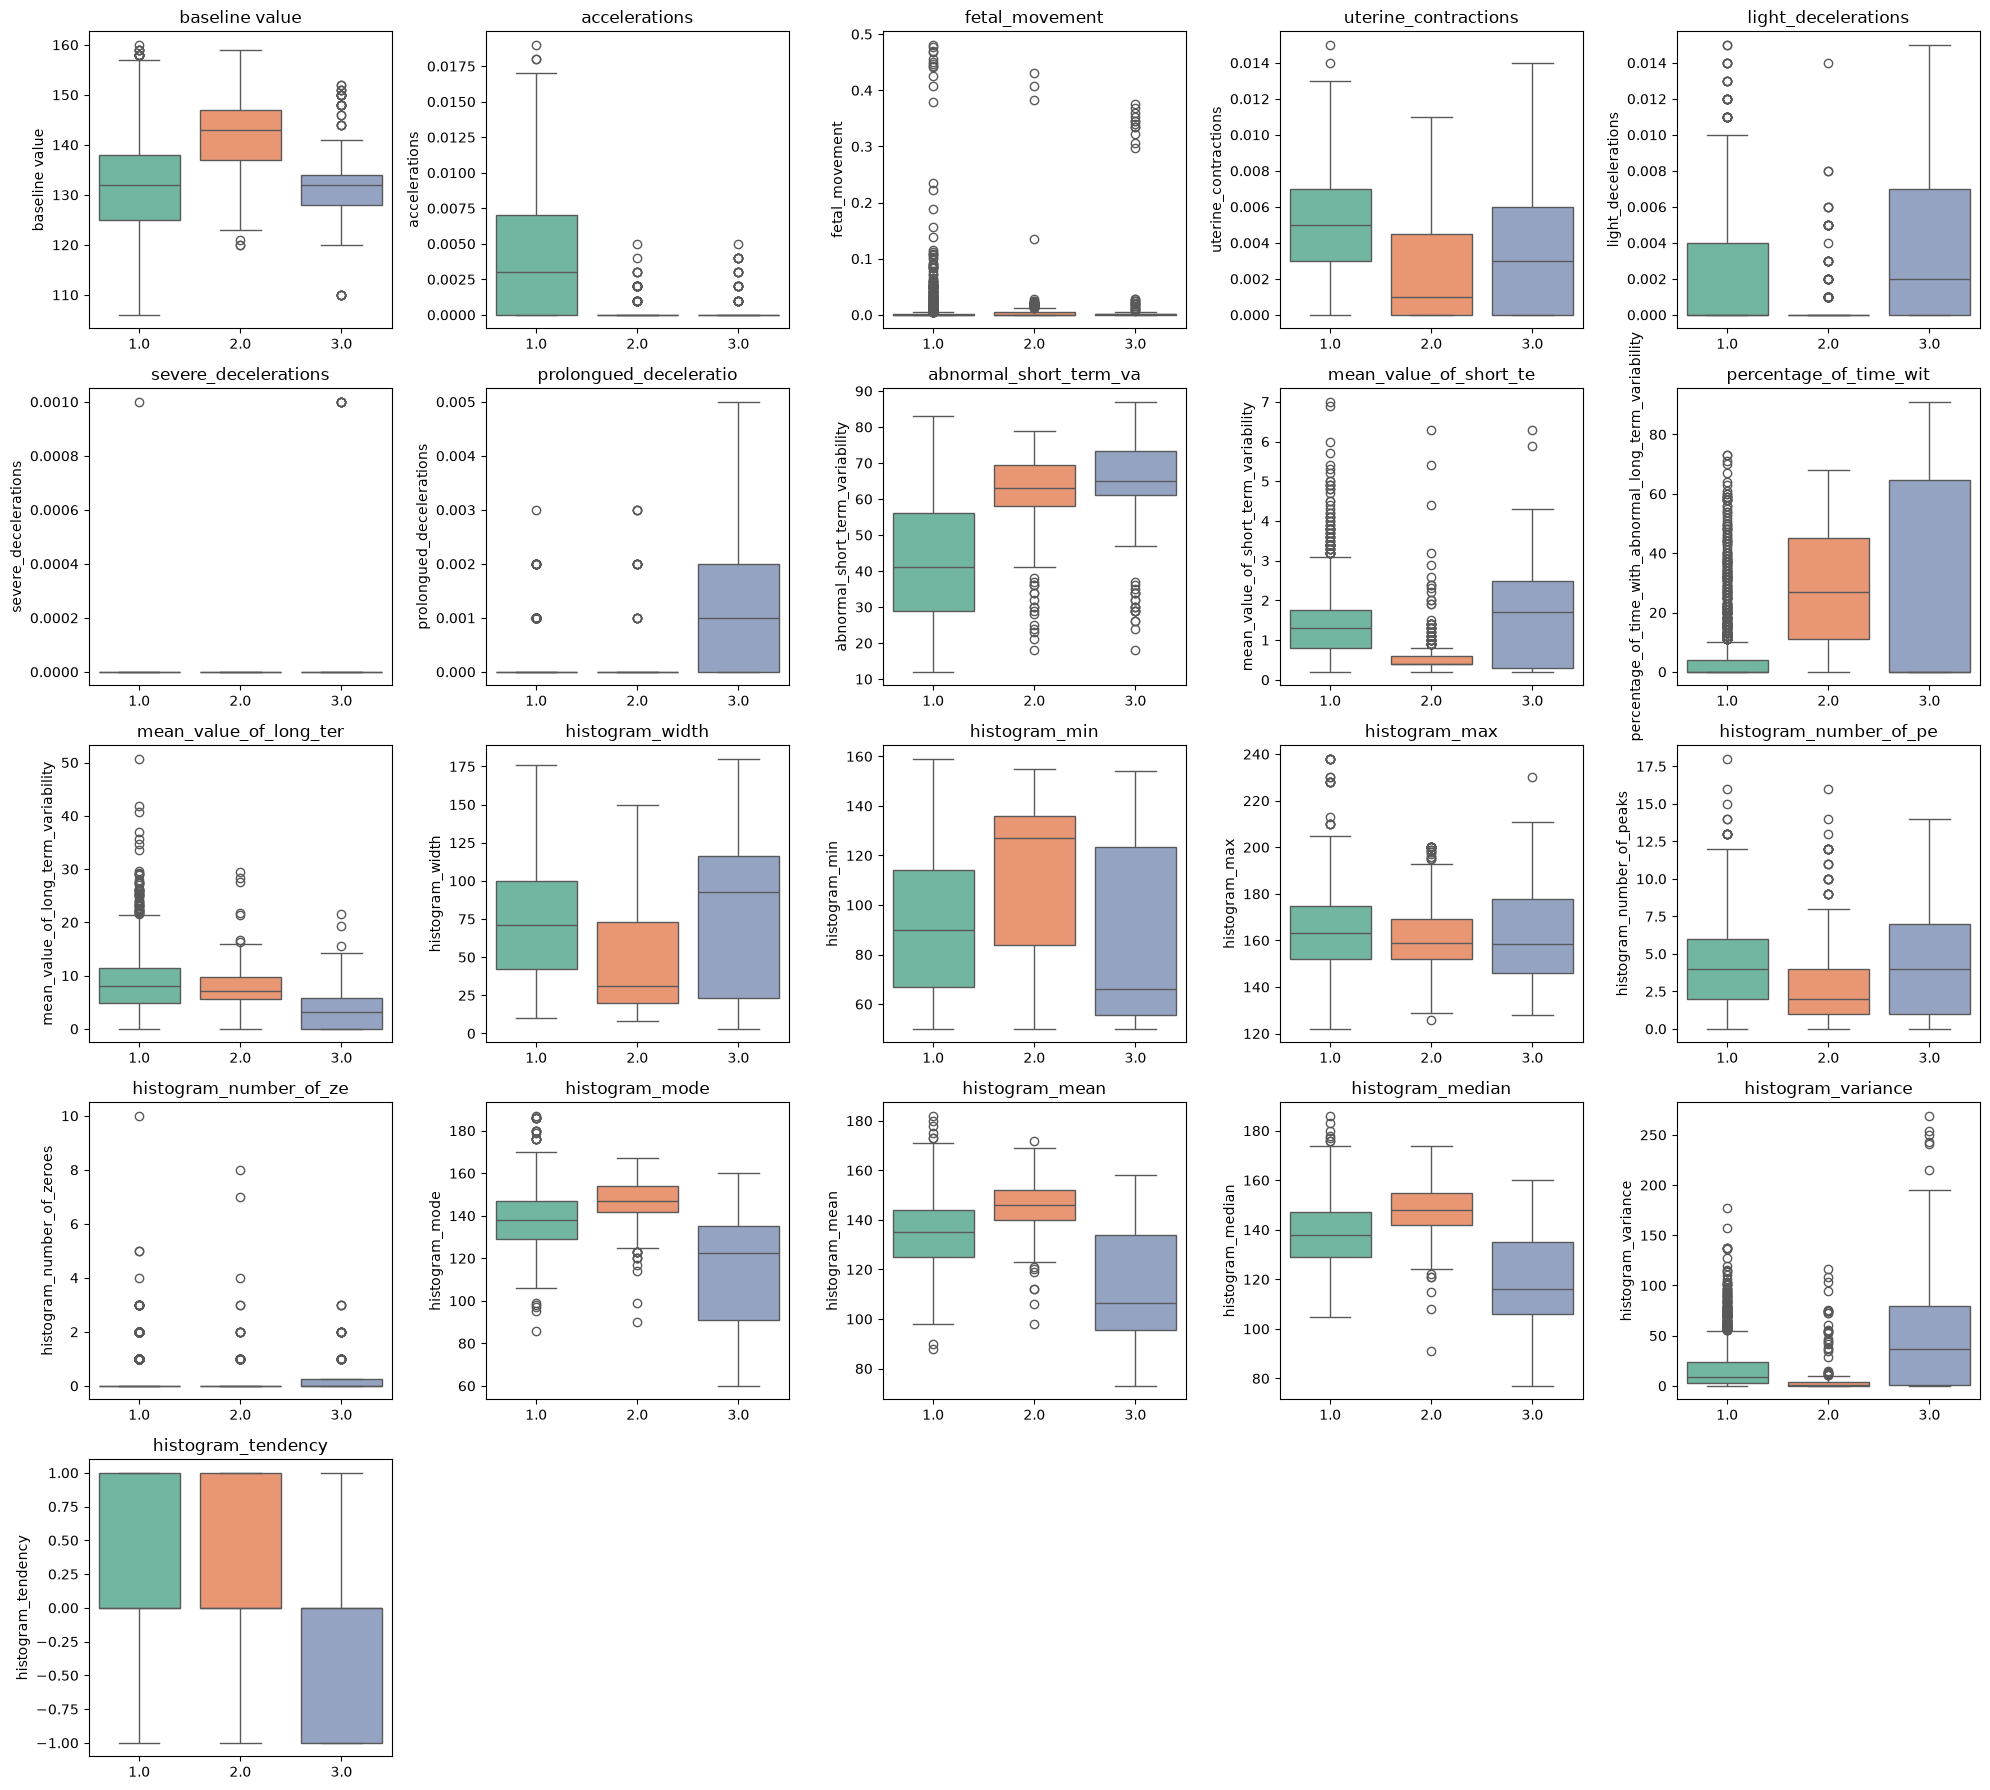

In [11]:
# 21 özelliğin tamamı için 5x5'lik grid (son 4'ü boş kalacak şekilde)
fig2, axes2 = plt.subplots(nrows=5, ncols=5, figsize=(20, 18))
axes2 = axes2.flatten()

for i, col in enumerate(features):
    # x eksenine sınıfları (fetal_health), y eksenine ise değeri veriyoruz
    sns.boxplot(x='fetal_health', y=col, data=df, ax=axes2[i], palette='Set2')
    axes2[i].set_title(col[:22])
    axes2[i].set_xlabel('')

# Geriye kalan 4 boş grafiği temizle
for j in range(len(features), len(axes2)):
    fig2.delaxes(axes2[j])

plt.tight_layout()
plt.show()

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler
from sklearn.pipeline import Pipeline
import joblib

# 1. Tekrar eden 13 satırı temizle
df = df.drop_duplicates().reset_index(drop=True)

# 2. Özellikler (X) ve Hedef Değişken (y) ayrımı
X = df.drop('fetal_health', axis=1)
# PyTorch CrossEntropyLoss için etiketleri (1, 2, 3) -> (0, 1, 2) yapıyoruz
y = (df['fetal_health'] - 1).astype(int)

# 3. Stratified Train-Test Split (Sınıf dağılım oranlarını koruyarak ayırma)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Opsiyonel: Çok aşırı uçları (yalnızca %99.5 üstünü) satır silmeden baskılama (Clipping)
# Sadece train setinin sınırlarını öğrenip hem train hem test'e uyguluyoruz (Data Leakage önlemi)
upper_limits = X_train.quantile(0.995)
X_train_clipped = X_train.clip(upper=upper_limits, axis=1)
X_test_clipped = X_test.clip(upper=upper_limits, axis=1)

# 5. Ölçeklendirme (Outlier etkisini azaltmak için RobustScaler + StandardScaler birlikte kullanılabilir)
scaler = Pipeline([
    ('robust', RobustScaler()),
    ('standard', StandardScaler())
])

X_train_scaled = scaler.fit_transform(X_train_clipped)
X_test_scaled = scaler.transform(X_test_clipped)

# Web uygulamasında kullanmak üzere scaler'ı kaydet
joblib.dump(scaler, 'scaler.pkl')
print("Eğitim verisi boyutu:", X_train_scaled.shape)
print("Test verisi boyutu:", X_test_scaled.shape)

Eğitim verisi boyutu: (1690, 21)
Test verisi boyutu: (423, 21)


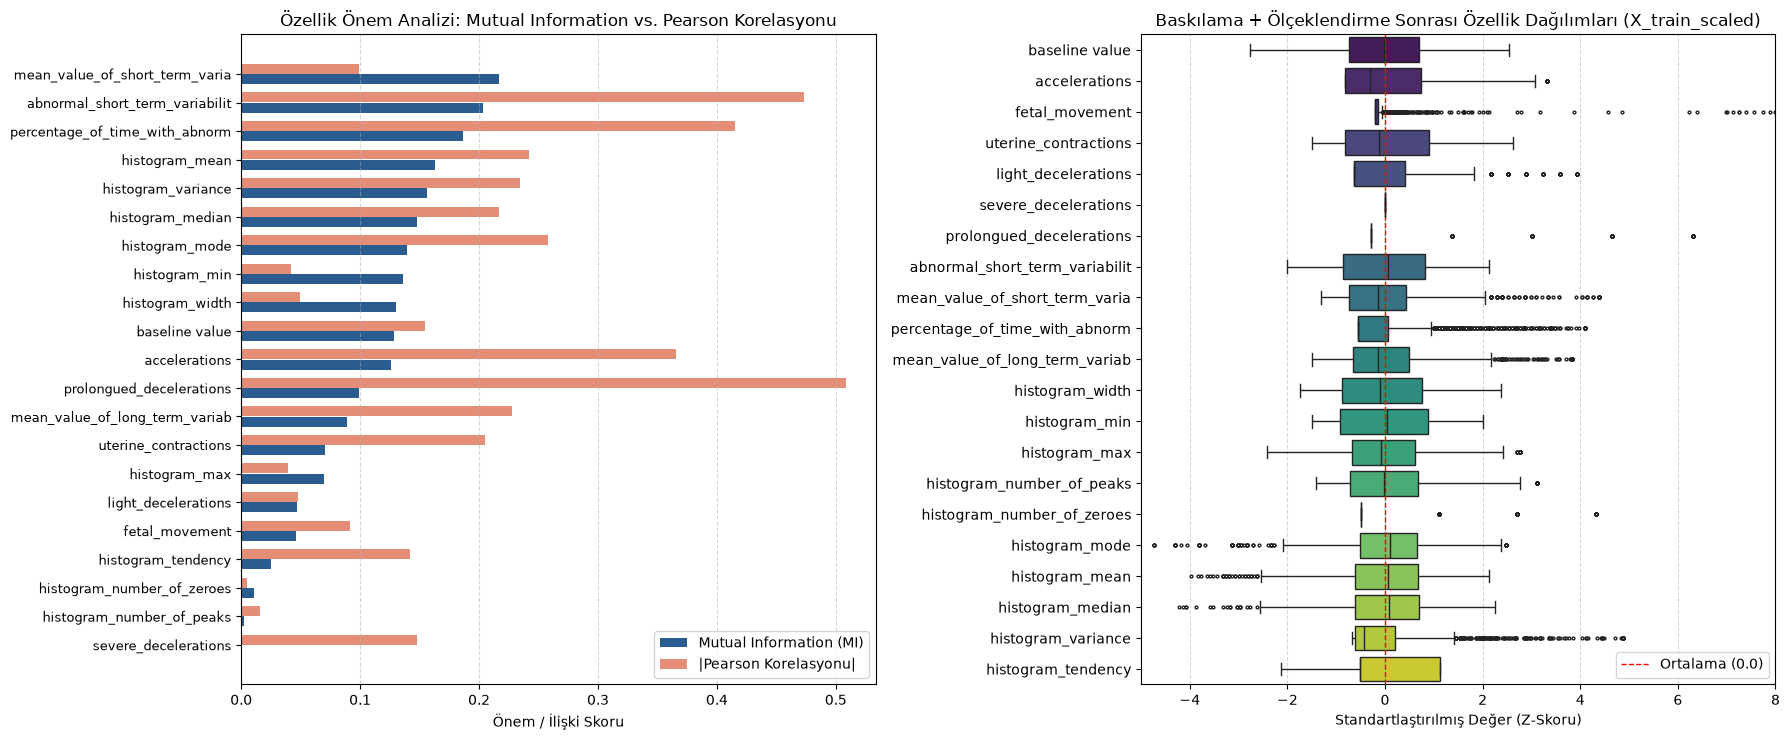

In [13]:
from sklearn.feature_selection import mutual_info_classif

# 1. Mutual Information (Doğrusal Olmayan Bilgi Kazancı) Hesaplama
mi_scores = mutual_info_classif(X_train_scaled, y_train, random_state=42)
corr_with_target = X_train.corrwith(y_train).abs()

comp_df = pd.DataFrame({
    'Feature': X.columns,
    'Mutual_Information': mi_scores,
    'Abs_Pearson_Corr': corr_with_target.values
}).sort_values(by='Mutual_Information', ascending=True)

# 2. Yan Yana Görselleştirme: MI vs Pearson ve X_train_scaled Boxplot
fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))

y_pos = np.arange(len(comp_df))
axes[0].barh(y_pos - 0.18, comp_df['Mutual_Information'], height=0.35, label='Mutual Information (MI)', color='#2b5c8f')
axes[0].barh(y_pos + 0.18, comp_df['Abs_Pearson_Corr'], height=0.35, label='|Pearson Korelasyonu|', color='#e07a5f', alpha=0.85)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([f[:30] for f in comp_df['Feature']], fontsize=9)
axes[0].set_xlabel('Önem / İlişki Skoru')
axes[0].set_title('Özellik Önem Analizi: Mutual Information vs. Pearson Korelasyonu')
axes[0].legend(loc='lower right')
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Ölçeklendirme sonrası tüm özelliklerin Z-skoru dağılımı
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=[col[:30] for col in X.columns])
sns.boxplot(data=X_train_scaled_df, orient='h', ax=axes[1], palette='viridis', fliersize=2)
axes[1].set_title('Baskılama + Ölçeklendirme Sonrası Özellik Dağılımları (X_train_scaled)')
axes[1].set_xlabel('Standartlaştırılmış Değer (Z-Skoru)')
axes[1].set_xlim(-5, 8)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1, label='Ortalama (0.0)')
axes[1].legend(loc='lower right')
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

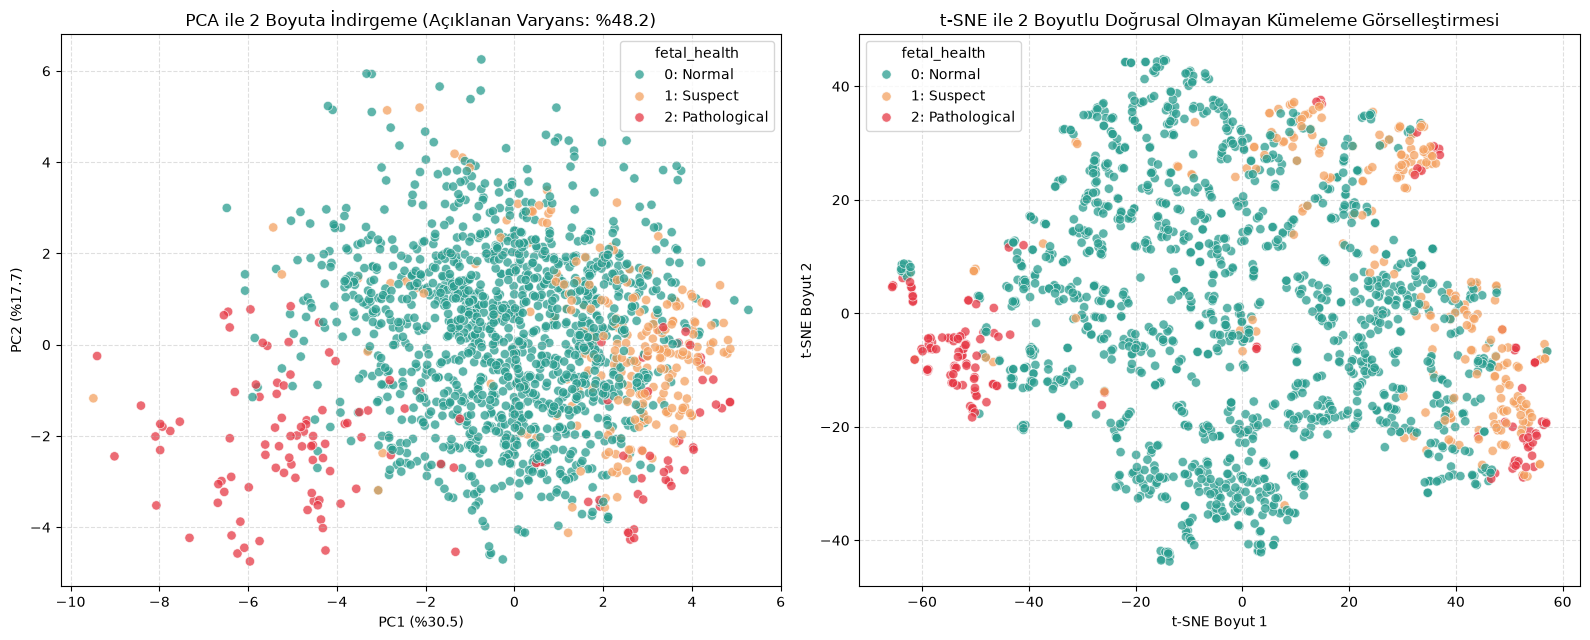

In [14]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# PCA ve t-SNE modelleri (Sadece eğitim verisi üzerinde)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_train_scaled)

tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_train_scaled)

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
class_labels = y_train.map({0: '0: Normal', 1: '1: Suspect', 2: '2: Pathological'})
palette_map = {'0: Normal': '#2a9d8f', '1: Suspect': '#f4a261', '2: Pathological': '#e63946'}

# 1. PCA Scatterplot
sns.scatterplot(
    x=X_pca[:, 0], y=X_pca[:, 1], hue=class_labels,
    hue_order=['0: Normal', '1: Suspect', '2: Pathological'],
    palette=palette_map, alpha=0.75, s=45, ax=axes[0]
)
axes[0].set_title(f'PCA ile 2 Boyuta İndirgeme (Açıklanan Varyans: %{pca.explained_variance_ratio_.sum()*100:.1f})')
axes[0].set_xlabel(f'PC1 (%{pca.explained_variance_ratio_[0]*100:.1f})')
axes[0].set_ylabel(f'PC2 (%{pca.explained_variance_ratio_[1]*100:.1f})')
axes[0].grid(True, linestyle='--', alpha=0.4)

# 2. t-SNE Scatterplot
sns.scatterplot(
    x=X_tsne[:, 0], y=X_tsne[:, 1], hue=class_labels,
    hue_order=['0: Normal', '1: Suspect', '2: Pathological'],
    palette=palette_map, alpha=0.75, s=45, ax=axes[1]
)
axes[1].set_title('t-SNE ile 2 Boyutlu Doğrusal Olmayan Kümeleme Görselleştirmesi')
axes[1].set_xlabel('t-SNE Boyut 1')
axes[1].set_ylabel('t-SNE Boyut 2')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

In [15]:
pca_full = PCA(random_state=42).fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_ * 100)

for i in range(6):
    print(f"n_components={i+1} -> Kümülatif Varyans: %{cum_var[i]:.2f}")

n_components=1 -> Kümülatif Varyans: %30.51
n_components=2 -> Kümülatif Varyans: %48.21
n_components=3 -> Kümülatif Varyans: %57.56
n_components=4 -> Kümülatif Varyans: %65.03
n_components=5 -> Kümülatif Varyans: %71.08
n_components=6 -> Kümülatif Varyans: %75.90


In [16]:
import torch
from sklearn.utils.class_weight import compute_class_weight

# Cihaz (GPU/CPU) seçimi
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Eğitim setindeki sınıf dağılımına göre dengeli ağırlıkları hesapla
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# PyTorch CrossEntropyLoss içine doğrudan verebilmek için FloatTensor'a çevir
class_weights_tensor = torch.tensor(class_weights, dtype=torch.float32).to(device)
print("PyTorch Sınıf Ağırlıkları (0, 1, 2):", class_weights_tensor)

# Model eğitiminde kullanacağımız loss fonksiyonu:
criterion = torch.nn.CrossEntropyLoss(weight=class_weights_tensor)

PyTorch Sınıf Ağırlıkları (0, 1, 2): tensor([0.4281, 2.4074, 4.0238])


In [17]:
# Web arayüzündeki formda varsayılan (default) değerler ve sınırlar için istatistikleri kaydet
feature_stats = {
    col: {
        'min': float(X_train_clipped[col].min()),
        'median': float(X_train_clipped[col].median()),
        'max': float(X_train_clipped[col].max()),
        'upper_clip': float(upper_limits[col])
    }
    for col in X.columns
}
joblib.dump(feature_stats, 'feature_stats.pkl')

['feature_stats.pkl']

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# 1. NumPy dizilerini PyTorch tensörlerine çevirme
# Özellikler float32, hedef değişken (etiketler) ise Long (tam sayı) olmalıdır
# Etiketleri unfreeze/unsqueeze YAPMADAN doğrudan LongTensor olarak alıyoruz
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.long) # Multi-class için Long formatı şart

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# drop_last=True ile boyutu 1 olan tekli batch'lerin BatchNorm1d patlatmasını engelliyoruz
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Eğitim DataLoader batch sayısı: {len(train_loader)}")
print(f"Test DataLoader batch sayısı: {len(test_loader)}")

Eğitim DataLoader batch sayısı: 26
Test DataLoader batch sayısı: 7


In [19]:
import torch
import torch.nn as nn

class FetalHealthMLP(nn.Module):
    def __init__(self, input_dim=21, num_classes=3):
        super(FetalHealthMLP, self).__init__()
        
        self.network = nn.Sequential(
            # 1. Gizli Katman
            nn.Linear(input_dim, 64),
            nn.BatchNorm1d(64), # Eğitimi kararlaştırmak için (opsiyonel ama çok faydalı)
            nn.ReLU(),
            nn.Dropout(0.3),    # Overfitting'i önlemek için %30 dropout
            
            # 2. Gizli Katman
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            # 3. Gizli Katman
            nn.Linear(32, 16),
            nn.ReLU(),
            
            # Çıktı Katmanı (3 sınıf için logitler döner)
            nn.Linear(16, num_classes)
        )

    def forward(self, x):
        return self.network(x)

# Modeli oluşturma
model = FetalHealthMLP(input_dim=21, num_classes=3)
print(model)

FetalHealthMLP(
  (network): Sequential(
    (0): Linear(in_features=21, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=32, out_features=16, bias=True)
    (9): ReLU()
    (10): Linear(in_features=16, out_features=3, bias=True)
  )
)


In [ ]:
#!pip install torchinfo
from torchinfo import summary

summary(model, input_size=(64, 21), col_names=["input_size", "output_size", "num_params", "trainable"])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Trainable
FetalHealthMLP                           [64, 21]                  [64, 3]                   --                        True
├─Sequential: 1-1                        [64, 21]                  [64, 3]                   --                        True
│    └─Linear: 2-1                       [64, 21]                  [64, 64]                  1,408                     True
│    └─BatchNorm1d: 2-2                  [64, 64]                  [64, 64]                  128                       True
│    └─ReLU: 2-3                         [64, 64]                  [64, 64]                  --                        --
│    └─Dropout: 2-4                      [64, 64]                  [64, 64]                  --                        --
│    └─Linear: 2-5                       [64, 64]                  [64, 32]                  2,080                     True
│    └─

In [ ]:
import random
import torch.optim as optim
#!pip install torchmetrics
import torchmetrics

# --- 1. RASTGELELİK TOHUMUNU SABİTLEME (RANDOM SEED) ---
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        # Deterministik davranış için (biraz yavaşlatabilir ama tam tekrarlanabilirlik sağlar)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# --- 2. MODEL, LOSS VE OPTİMİZATÖR TANIMLAMALARI ---
model = FetalHealthMLP(input_dim=21, num_classes=3).to(device)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

# --- 3. TORCHMETRICS İLE BAŞARI ÖLÇÜMÜ ---
# 3 sınıfımız olduğu için task='multiclass' ve num_classes=3 belirtiyoruz
train_accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=3).to(device)
test_accuracy_metric = torchmetrics.Accuracy(task="multiclass", num_classes=3).to(device)

# Eğitim Fonksiyonu

def train_epoch(model, dataloader, criterion, optimizer, metric, device):
    model.train()
    total_loss = 0.0
    metric.reset() # Her epoch başında metrik sayacını sıfırla
    
    for inputs, labels in dataloader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * inputs.size(0)
        
        # Torchmetrics ile tahminleri güncelle
        preds = torch.argmax(outputs, dim=1)
        metric.update(preds, labels)
        
    epoch_loss = total_loss / len(dataloader.dataset)
    epoch_acc = metric.compute() # Epoch sonu toplam Accuracy'yi hesapla
    return epoch_loss, epoch_acc.item()

# Test / Değerlendirme Fonksiyonu
def evaluate(model, dataloader, criterion, metric, device):
    model.eval()
    total_loss = 0.0
    metric.reset()
    
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            total_loss += loss.item() * inputs.size(0)
            
            preds = torch.argmax(outputs, dim=1)
            metric.update(preds, labels)
            
    epoch_loss = total_loss / len(dataloader.dataset)
    epoch_acc = metric.compute()
    return epoch_loss, epoch_acc.item()

# --- 4. EĞİTİM DÖNGÜSÜ ---

epochs = 50
best_test_acc = 0.0

history = {'train_loss': [], 'train_acc': [], 'test_loss': [], 'test_acc': []}

print("Torchmetrics destekli model eğitimi başlatılıyor...\n")
for epoch in range(epochs):
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, train_accuracy_metric, device)
    test_loss, test_acc = evaluate(model, test_loader, criterion, test_accuracy_metric, device)
    
    # Her epoch'un sonuçlarını history sözlüğüne kaydediyoruz
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)
    
    if test_acc > best_test_acc:
        best_test_acc = test_acc
        torch.save(model.state_dict(), 'best_fetal_model.pth')
        
    if (epoch + 1) % 10 == 0 or epoch == 0:
        print(f"Epoch [{epoch+1}/{epochs}] | "
              f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
              f"Test Loss: {test_loss:.4f} - Test Acc: {test_acc*100:.2f}%")

print(f"\nEğitim tamamlandı! En iyi Test Doğruluğu (Torchmetrics): %{best_test_acc*100:.2f}")

Rastgelelik tohumu (Seed = 42) sabitlendi.
Torchmetrics destekli model eğitimi başlatılıyor...

Epoch [1/50] | Train Loss: 1.0569 - Train Acc: 26.74% | Test Loss: 0.9989 - Test Acc: 40.90%
Epoch [10/50] | Train Loss: 0.4167 - Train Acc: 84.56% | Test Loss: 0.3739 - Test Acc: 86.52%
Epoch [20/50] | Train Loss: 0.3422 - Train Acc: 86.54% | Test Loss: 0.3058 - Test Acc: 87.47%
Epoch [30/50] | Train Loss: 0.2913 - Train Acc: 87.02% | Test Loss: 0.2767 - Test Acc: 91.02%
Epoch [40/50] | Train Loss: 0.2905 - Train Acc: 87.92% | Test Loss: 0.2444 - Test Acc: 89.13%
Epoch [50/50] | Train Loss: 0.2603 - Train Acc: 88.64% | Test Loss: 0.2430 - Test Acc: 90.31%

Eğitim tamamlandı! En iyi Test Doğruluğu (Torchmetrics): %91.02


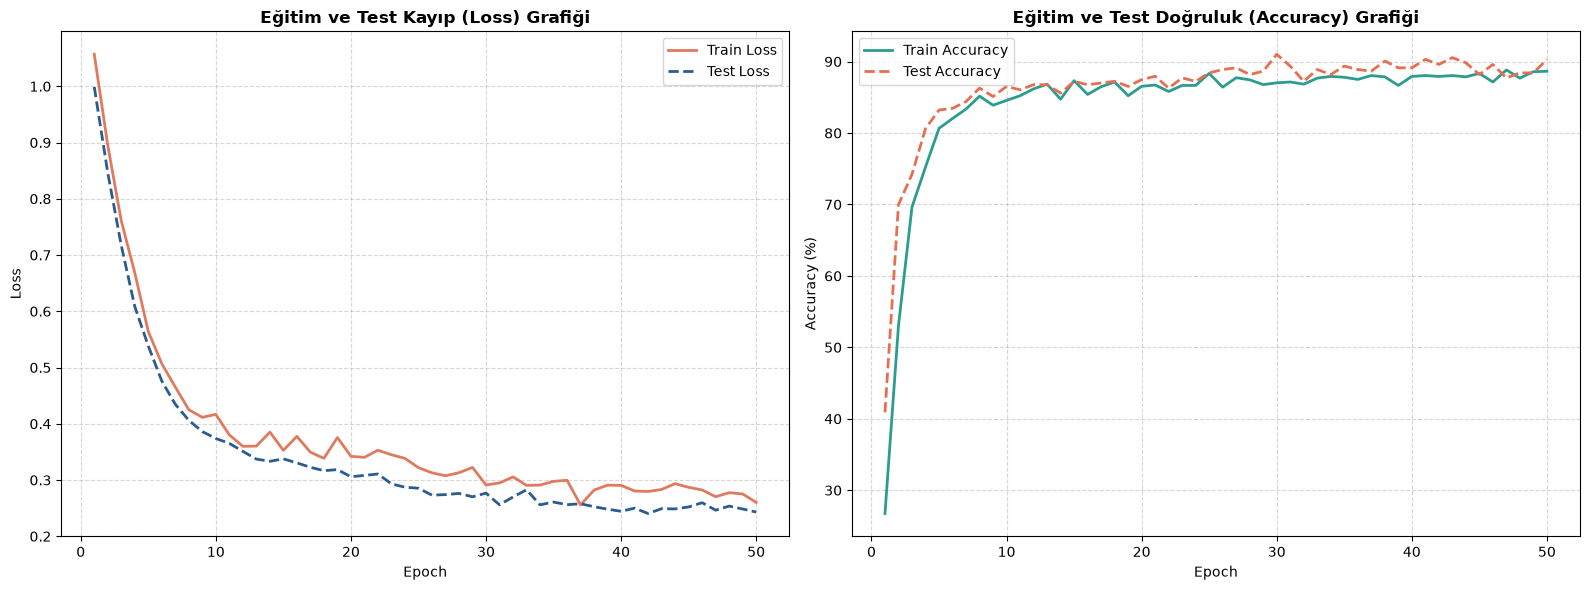

In [22]:
epochs_range = range(1, len(history['train_loss']) + 1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Grafik: Loss (Kayıp) Eğrisi
axes[0].plot(epochs_range, history['train_loss'], label='Train Loss', color='#e07a5f', linewidth=2)
axes[0].plot(epochs_range, history['test_loss'], label='Test Loss', color='#2b5c8f', linewidth=2, linestyle='--')
axes[0].set_title('Eğitim ve Test Kayıp (Loss) Grafiği', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch', fontsize=10)
axes[0].set_ylabel('Loss', fontsize=10)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# 2. Grafik: Accuracy (Doğruluk) Eğrisi
axes[1].plot(epochs_range, [acc * 100 for acc in history['train_acc']], label='Train Accuracy', color='#2a9d8f', linewidth=2)
axes[1].plot(epochs_range, [acc * 100 for acc in history['test_acc']], label='Test Accuracy', color='#e76f51', linewidth=2, linestyle='--')
axes[1].set_title('Eğitim ve Test Doğruluk (Accuracy) Grafiği', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch', fontsize=10)
axes[1].set_ylabel('Accuracy (%)', fontsize=10)
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Sinir ağı mimarisi 'fetal_health_mlp_architecture.png' olarak başarıyla kaydedildi.


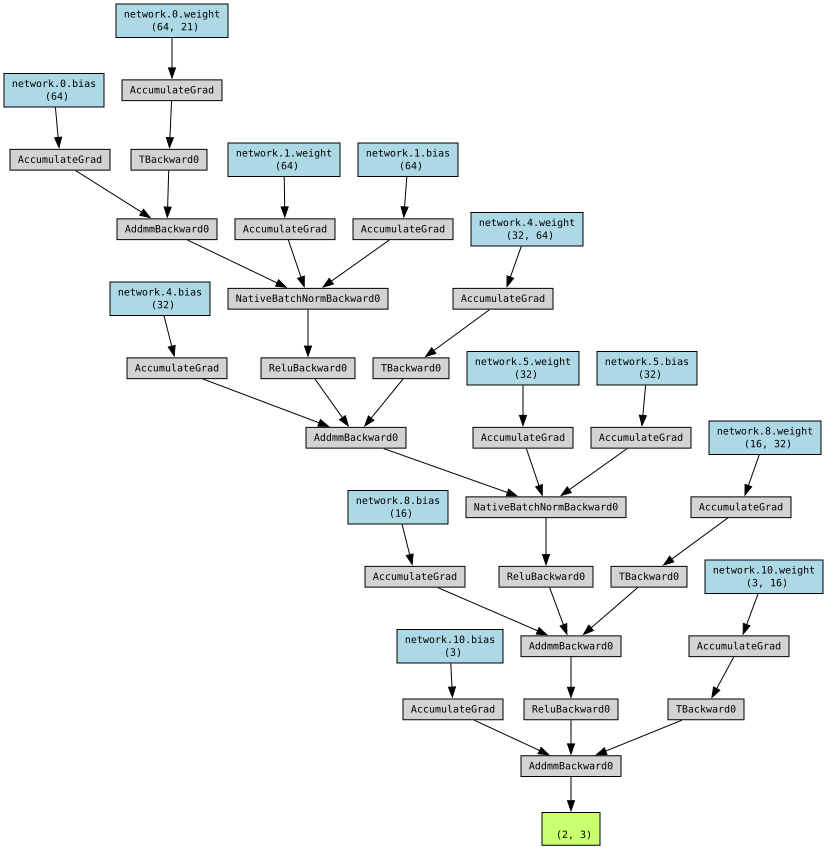

In [24]:
import os
# Graphviz'in Windows'taki varsayılan kurulum yolu
os.environ["PATH"] += os.pathsep + r'C:\Program Files\Graphviz\bin'

from torchviz import make_dot
import torch

# 1. Modeli ve cihazı kontrol edelim (eğittiğimiz modelin aktif olduğunu varsayıyoruz)
model.eval()

# 2. BatchNorm1d hatası almamak için batch_size >= 2 olan örnek bir girdi (dummy input) oluşturuyoruz
x_dummy = torch.randn(2, 21).to(device) 

# 3. İleri yayılımı (forward pass) tetikleyerek tahmin alıyoruz
y_pred = model(x_dummy)

# 4. Hesaplama grafiğini oluşturuyoruz
dot = make_dot(y_pred, params=dict(model.named_parameters()))

# 5. Görseli dosya olarak kaydedip ekrana çizdiriyoruz
dot.format = 'png'
dot.render('fetal_health_mlp_architecture')

print("Sinir ağı mimarisi 'fetal_health_mlp_architecture.png' olarak başarıyla kaydedildi.")
dot

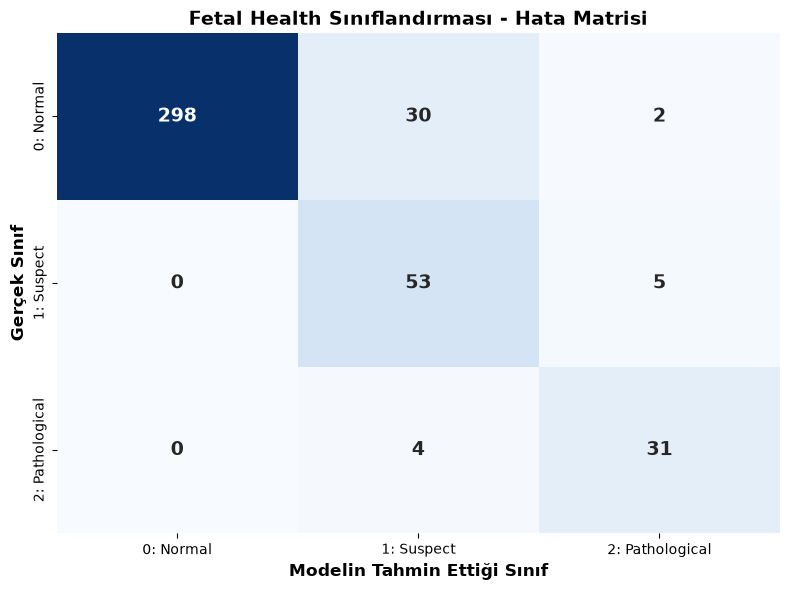


--- Sınıflandırma Raporu (Classification Report) ---
                 precision    recall  f1-score   support

      0: Normal       1.00      0.90      0.95       330
     1: Suspect       0.61      0.91      0.73        58
2: Pathological       0.82      0.89      0.85        35

       accuracy                           0.90       423
      macro avg       0.81      0.90      0.84       423
   weighted avg       0.93      0.90      0.91       423



In [25]:
from sklearn.metrics import confusion_matrix, classification_report

# 1. Test seti üzerinde tahminleri toplama
model.eval()
y_true = []
y_pred_list = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        
        # En yüksek olasılığa sahip sınıfı seçiyoruz
        preds = torch.argmax(outputs, dim=1)
        
        # Tensörleri CPU'ya ve numpy dizisine çevirip listeye ekliyoruz
        y_true.extend(labels.cpu().numpy())
        y_pred_list.extend(preds.cpu().numpy())

# 2. Karmaşıklık Matrisi (Confusion Matrix) Hesaplama
cm = confusion_matrix(y_true, y_pred_list)
class_names = ['0: Normal', '1: Suspect', '2: Pathological']

# 3. Matrisi Görselleştirme
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 14, "weight": "bold"})

plt.xlabel('Modelin Tahmin Ettiği Sınıf', fontsize=12, fontweight='bold')
plt.ylabel('Gerçek Sınıf', fontsize=12, fontweight='bold')
plt.title('Fetal Health Sınıflandırması - Hata Matrisi', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# 4. Sınıf Bazlı Detaylı Metrik Raporu
print("\n--- Sınıflandırma Raporu (Classification Report) ---")
print(classification_report(y_true, y_pred_list, target_names=class_names))